In [1]:
import pandas as pd
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D

In [9]:
# CSV не сохраняет тип datetime: восстанавливаем его при чтении.
df_research = pd.read_csv(
    'abortion_research_data.csv.gz',
    parse_dates=['date'],
    dtype={'person_id': 'string'},
)
df_research['date'] = df_research['date'].dt.to_period('M').dt.to_timestamp()
df_research

,SSUID,PNUM,reference_year,MONTHCODE,SPANEL,SWAVE,TEHC_ST,TST_INTV,TMOVER,income,...,restriction_month_end,restriction_share,restriction_days_confirmed,restriction_days_uncertain,policy_uncertain,policy_covered,date,state,female_flag,person_id
0,11428577022,101,2021,1,2022,1,20,20.0,NaN,4131.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2021-01-01,Kansas,1,00011428577022_101
1,11428577022,101,2021,2,2022,1,20,20.0,1.0,3612.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2021-02-01,Kansas,1,00011428577022_101
2,11428577022,101,2021,3,2022,1,20,20.0,1.0,3470.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2021-03-01,Kansas,1,00011428577022_101
3,11428577022,101,2021,4,2022,1,20,20.0,1.0,3523.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2021-04-01,Kansas,1,00011428577022_101
4,11428577022,101,2021,5,2022,1,20,20.0,1.0,3790.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2021-05-01,Kansas,1,00011428577022_101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
714991,88199599599922,201,2024,8,2022,4,6,6.0,1.0,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,2024-08-01,California,1,88199599599922_201
714992,88199599599922,201,2024,9,2022,4,6,6.0,1.0,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,2024-09-01,California,1,88199599599922_201
714993,88199599599922,201,2024,10,2022,4,6,6.0,1.0,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,2024-10-01,California,1,88199599599922_201
714994,88199599599922,201,2024,11,2022,4,6,6.0,1.0,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,2024-11-01,California,1,88199599599922_201


In [ ]:
# Только женщины с известными штатом и месяцем.
women_df = (
    df_research.loc[df_research['female_flag'].eq(1)]
    .dropna(subset=['state', 'date'])
    .copy()
)

women_df.columns

,SSUID,PNUM,reference_year,MONTHCODE,SPANEL,SWAVE,TEHC_ST,TST_INTV,TMOVER,income,...,restriction_month_end,restriction_share,restriction_days_confirmed,restriction_days_uncertain,policy_uncertain,policy_covered,date,state,female_flag,person_id
0,11428577022,101,2021,1,2022,1,20,20.0,NaN,4131.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2021-01-01,Kansas,1,00011428577022_101
1,11428577022,101,2021,2,2022,1,20,20.0,1.0,3612.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2021-02-01,Kansas,1,00011428577022_101
2,11428577022,101,2021,3,2022,1,20,20.0,1.0,3470.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2021-03-01,Kansas,1,00011428577022_101
3,11428577022,101,2021,4,2022,1,20,20.0,1.0,3523.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2021-04-01,Kansas,1,00011428577022_101
4,11428577022,101,2021,5,2022,1,20,20.0,1.0,3790.0,...,0.0,0.0,0.0,0.0,0.0,1.0,2021-05-01,Kansas,1,00011428577022_101
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
714991,88199599599922,201,2024,8,2022,4,6,6.0,1.0,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,2024-08-01,California,1,88199599599922_201
714992,88199599599922,201,2024,9,2022,4,6,6.0,1.0,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,2024-09-01,California,1,88199599599922_201
714993,88199599599922,201,2024,10,2022,4,6,6.0,1.0,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,2024-10-01,California,1,88199599599922_201
714994,88199599599922,201,2024,11,2022,4,6,6.0,1.0,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,2024-11-01,California,1,88199599599922_201


In [14]:
# Календарь всего исследуемого периода.
calendar = pd.date_range(df_research['date'].min(), df_research['date'].max(), freq='MS')
plot_dates = calendar + pd.offsets.MonthEnd(0)
n_months = len(calendar)

# Средние считаются по текущей полной выборке женщин с известным штатом.
monthly = women_df.groupby(['state', 'date'], as_index=False, observed=True).agg(
    mean_income=('income', 'mean'),
    n_income=('income', 'count'),
    restriction_flag=('restriction_flag', 'first'),
)
n_by_state = monthly.groupby('state', observed=True)['n_income'].sum()
states = sorted(monthly['state'].unique())

# Сбалансированность — присутствие человека во всех календарных месяцах.
# Заполненность дохода не является условием включения в сбалансированную часть.
all_month_counts = df_research.groupby('person_id', observed=True)['date'].nunique()
balanced_ids_all = all_month_counts.index[all_month_counts.eq(n_months)]
n_balanced_people_all = len(balanced_ids_all)
n_balanced_rows_all = int(df_research['person_id'].isin(balanced_ids_all).sum())

# Для женщин дополнительно требуем female_flag=1 и известный штат во всех месяцах.
women_month_counts = women_df.groupby('person_id', observed=True)['date'].nunique()
balanced_ids_women = women_month_counts.index[women_month_counts.eq(n_months)]
balanced_women_df = women_df.loc[women_df['person_id'].isin(balanced_ids_women)]
n_balanced_women = len(balanced_ids_women)
n_balanced_rows_women = len(balanced_women_df)
n_balanced_income_women = int(balanced_women_df['income'].notna().sum())
assert n_balanced_rows_women == n_balanced_women * n_months

low = min(0, monthly['mean_income'].min())
high = max(0, monthly['mean_income'].max())
padding = max((high - low) * 0.06, 1)
colors = {0: '#2678B2', 1: '#D62728', -1: '#888888'}

def fmt_n(value):
    return f'{int(value):,}'.replace(',', ' ')

print(f'Период: {calendar.min():%Y-%m} — {calendar.max():%Y-%m}, {n_months} месяцев')
print(f'Сбалансированная панель: {fmt_n(n_balanced_people_all)} человек, '
      f'{fmt_n(n_balanced_rows_all)} наблюдений')
print(f'Сбалансированные женщины с известным штатом: {fmt_n(n_balanced_women)} человек, '
      f'{fmt_n(n_balanced_rows_women)} наблюдений, '
      f'из них {fmt_n(n_balanced_income_women)} с доходом')

Период: 2021-01 — 2024-12, 48 месяцев
Сбалансированная панель: 6 087 человек, 292 176 наблюдений
Сбалансированные женщины с известным штатом: 3 061 человек, 146 928 наблюдений, из них 63 034 с доходом


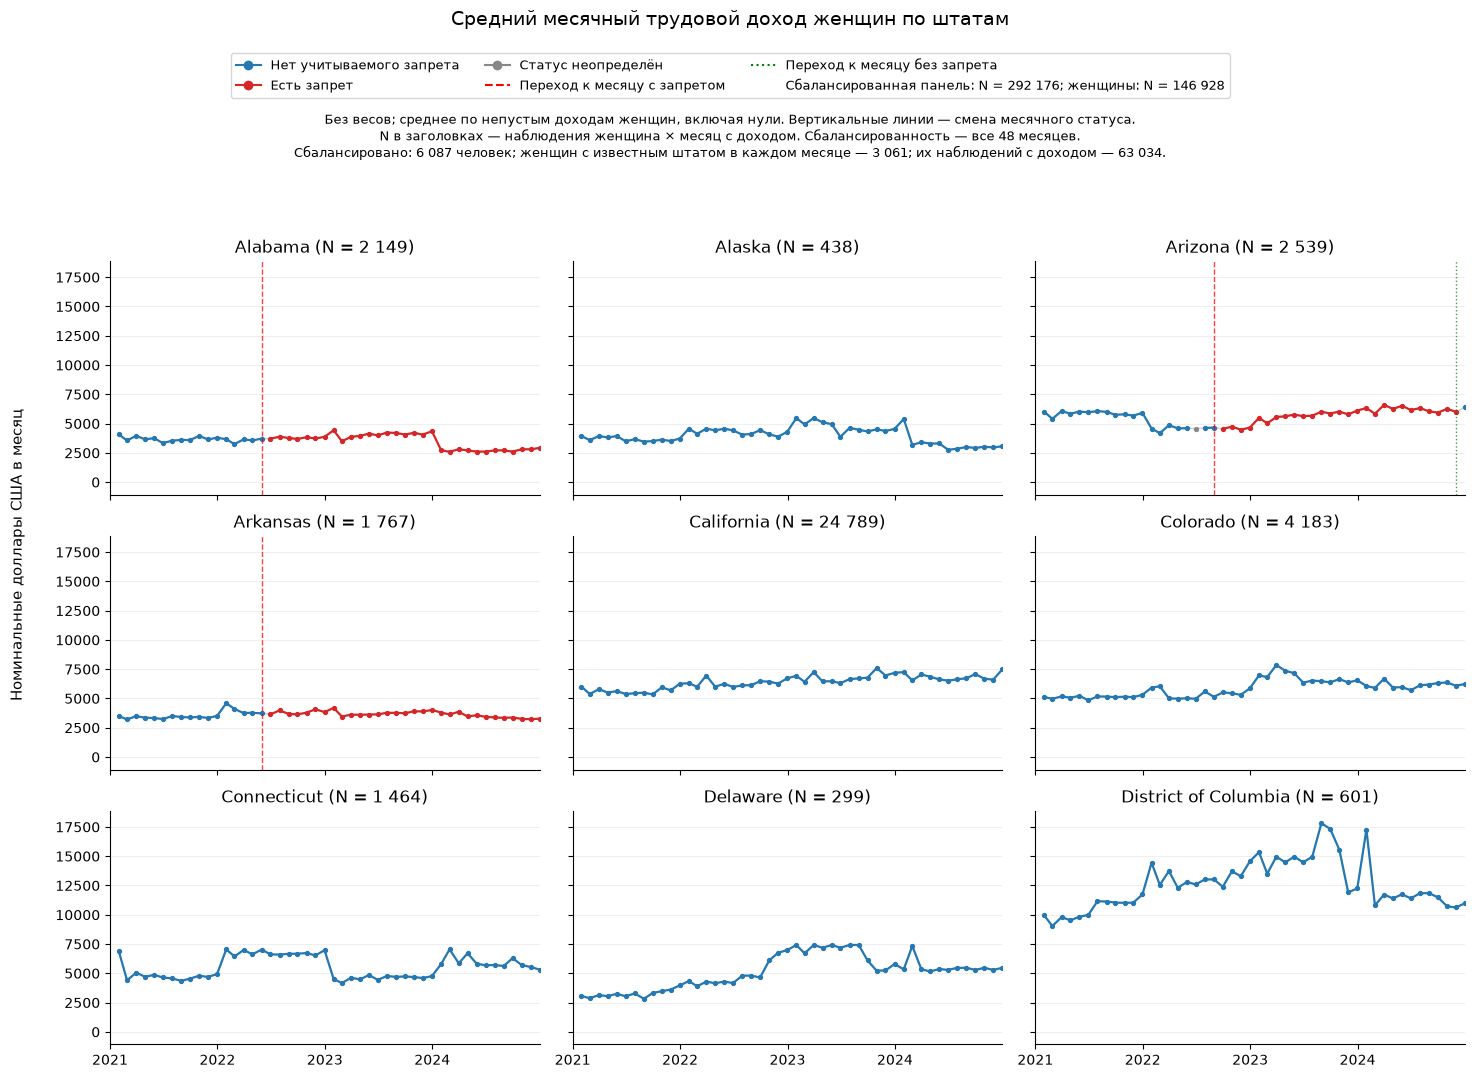

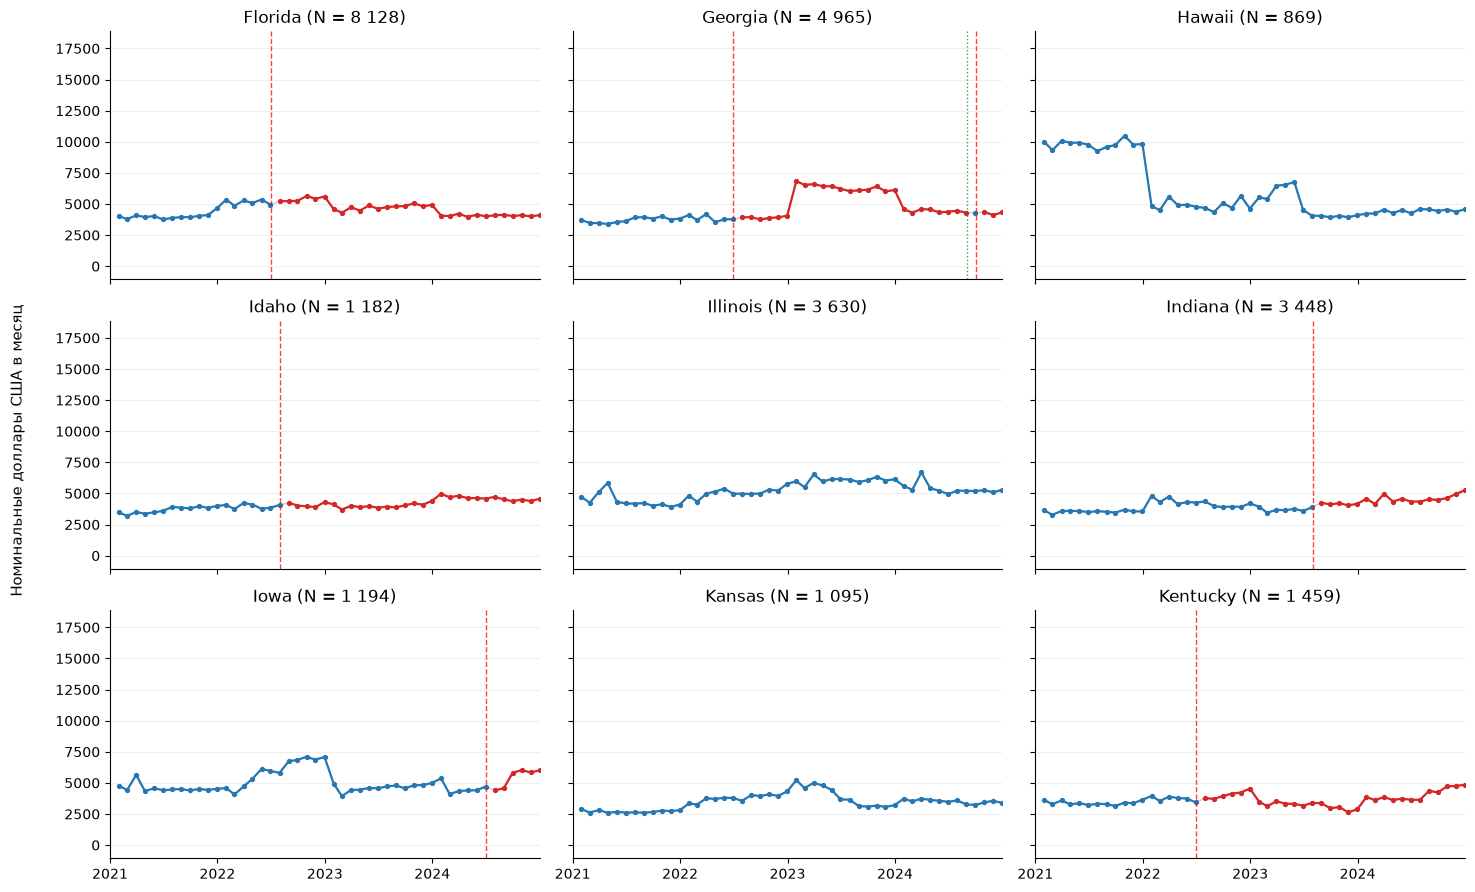

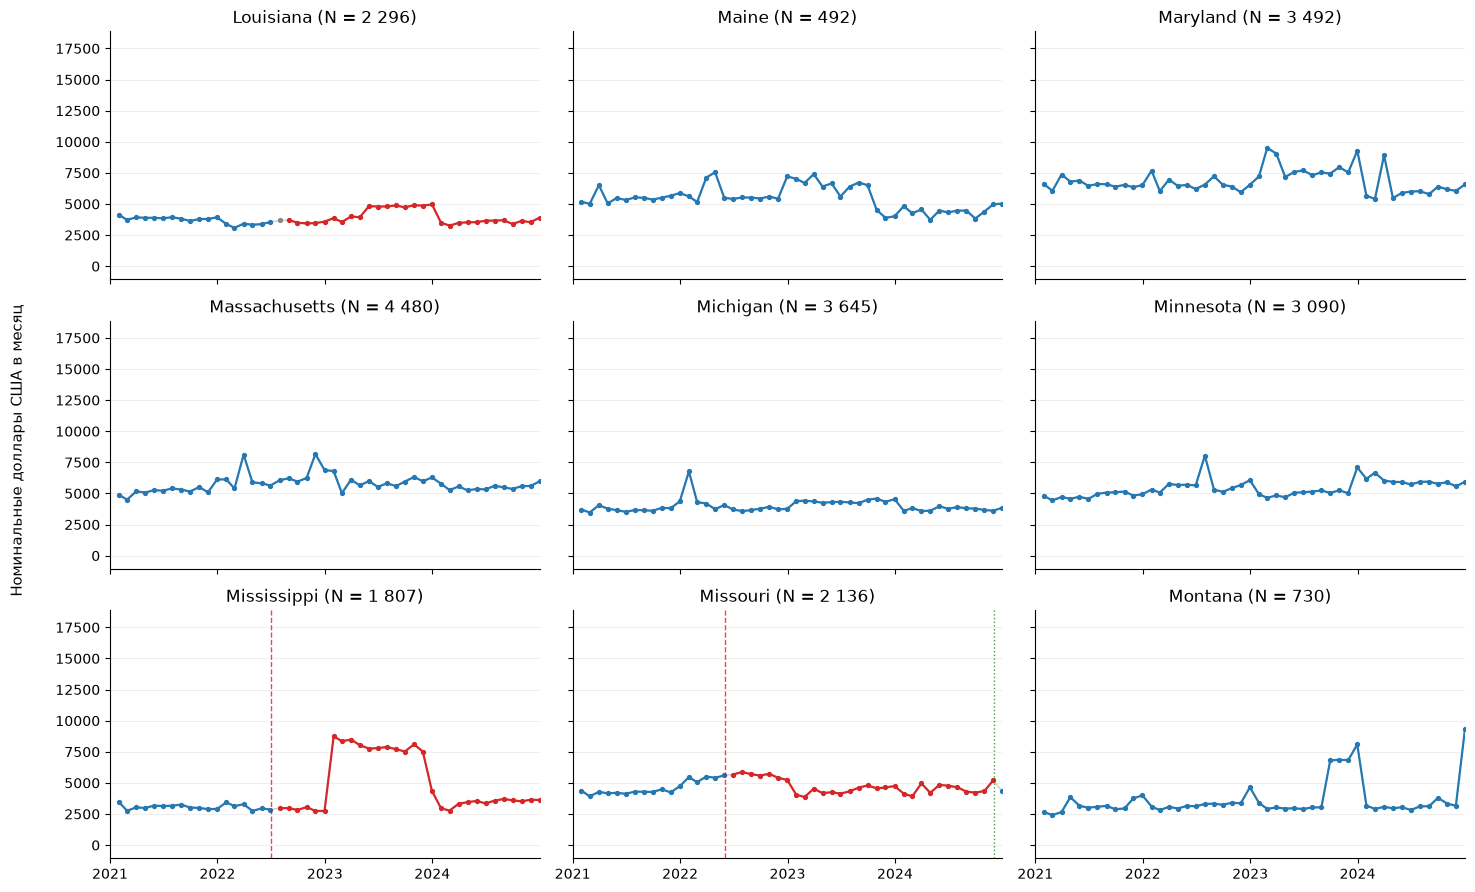

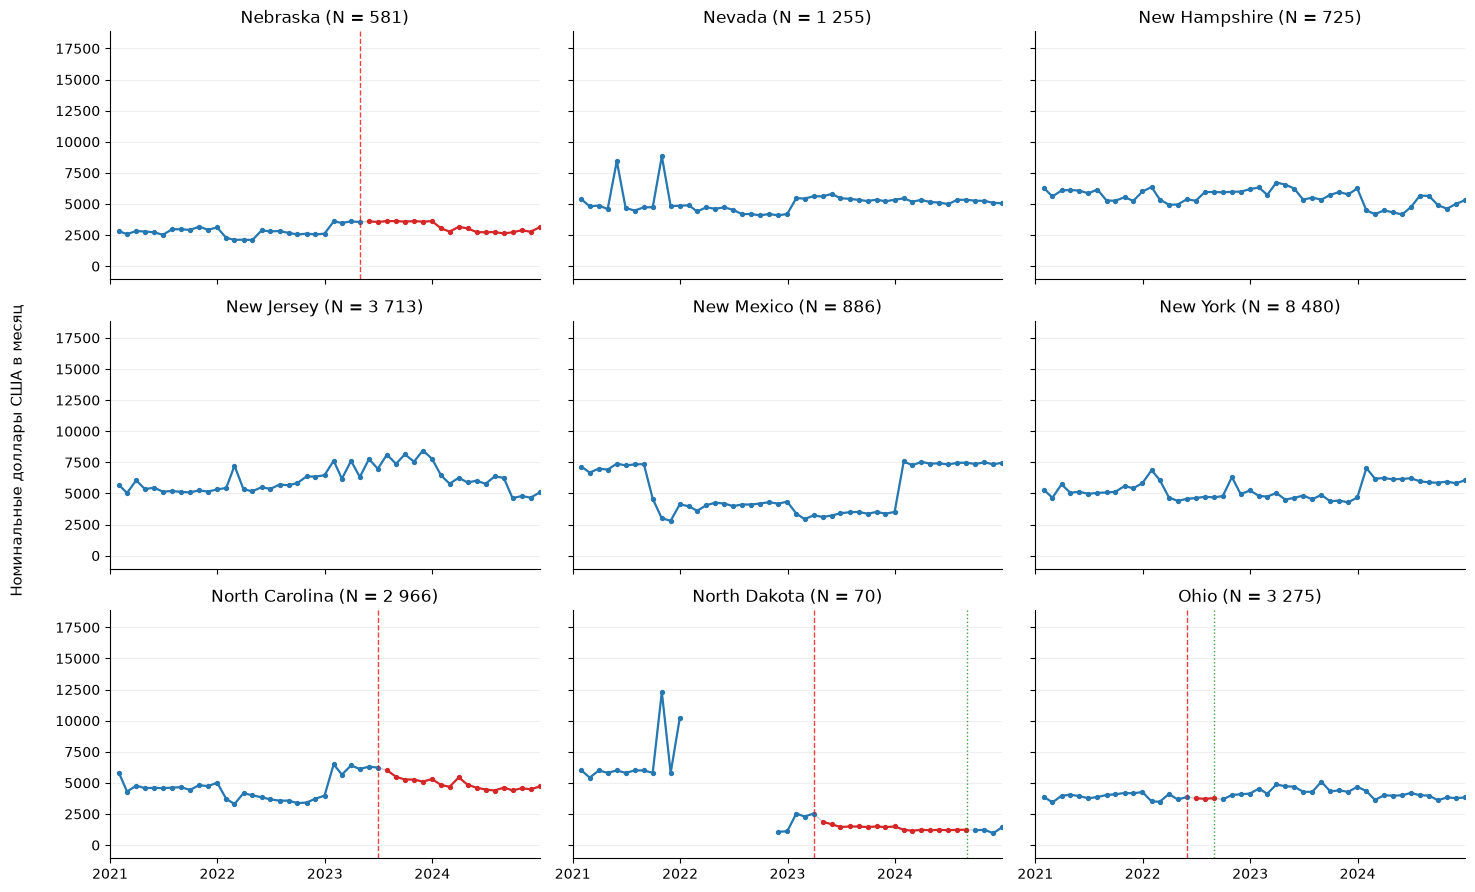

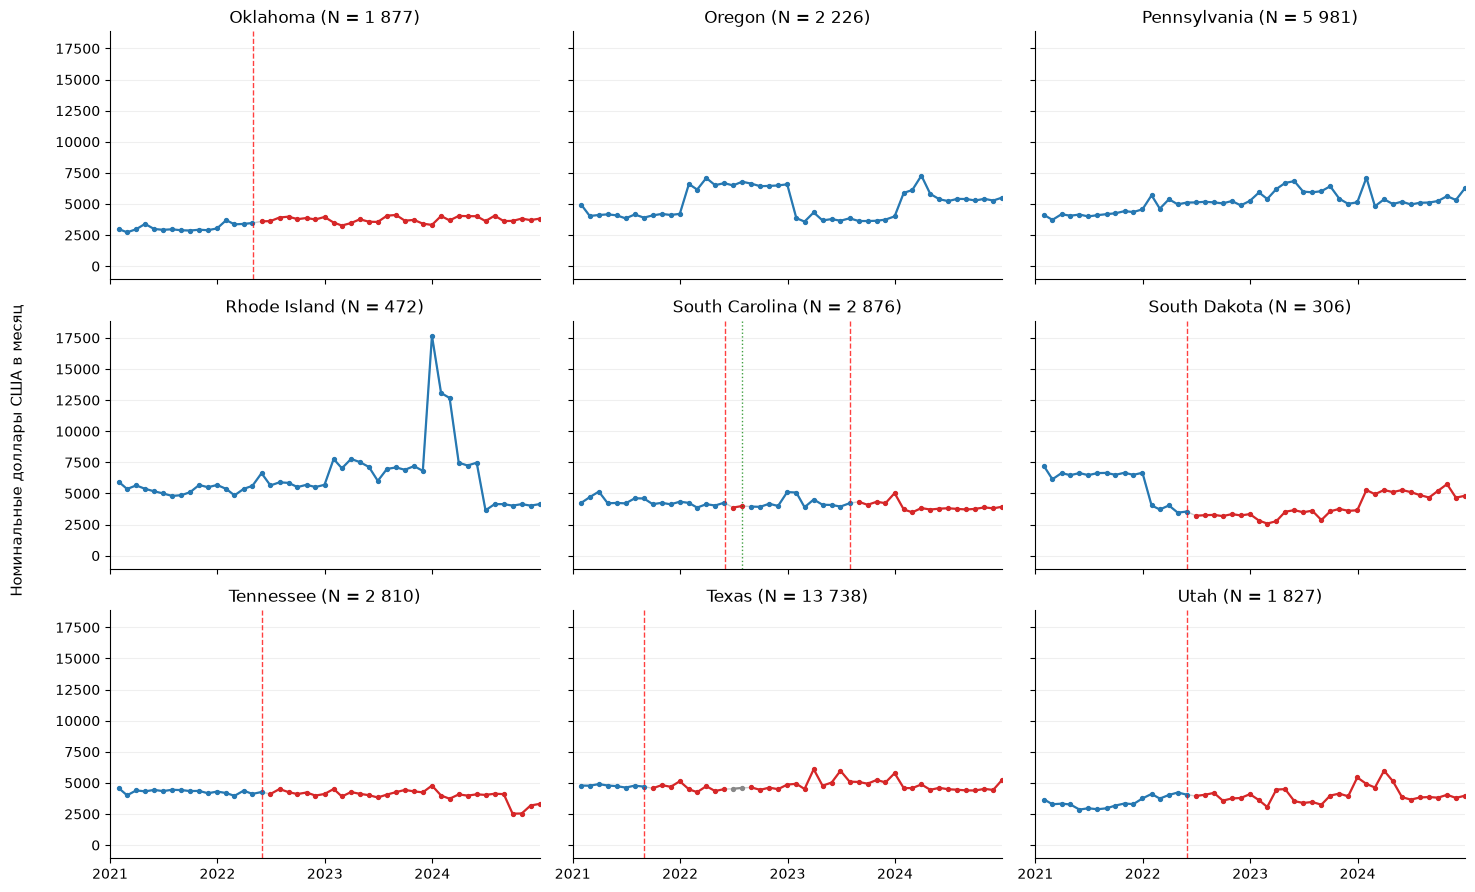

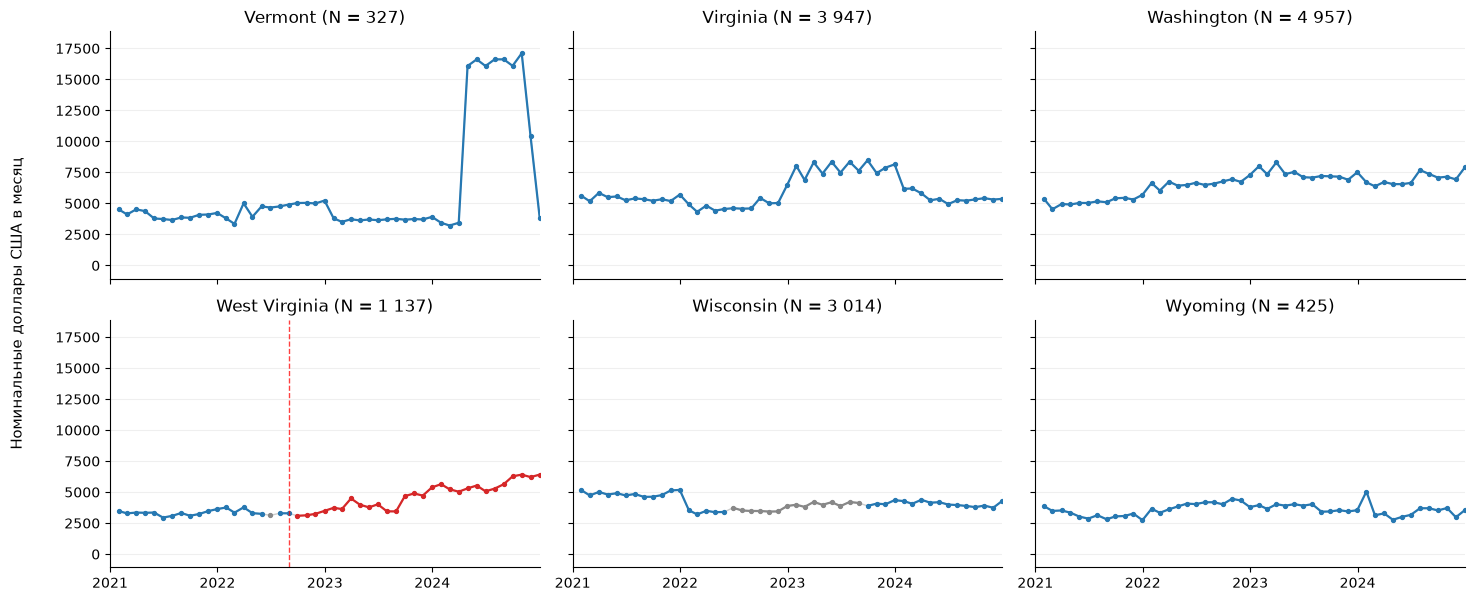

In [15]:
legend = [
    Line2D(
        [0], [0], color=colors[0], marker="o",
        label="Нет учитываемого запрета",
    ),
    Line2D(
        [0], [0], color=colors[1], marker="o",
        label="Есть запрет",
    ),
    Line2D(
        [0], [0], color=colors[-1], marker="o",
        label="Статус неопределён",
    ),
    Line2D(
        [0], [0], color="red", linestyle="--",
        label="Переход к месяцу с запретом",
    ),
    Line2D(
        [0], [0], color="green", linestyle=":",
        label="Переход к месяцу без запрета",
    ),
    Line2D(
        [], [], linestyle="none", color="none",
        label=(f"Сбалансированная панель: N = {fmt_n(n_balanced_rows_all)}; "
               f"женщины: N = {fmt_n(n_balanced_rows_women)}"),
    ),
]

# По 9 штатов на страницу
for offset in range(0, len(states), 9):
    page = states[offset:offset + 9]
    nrows = (len(page) + 2) // 3
    first_page = offset == 0

    fig, axes = plt.subplots(
        nrows, 3,
        figsize=(15, 3 * nrows + (2.0 if first_page else 0.3)),
        sharex=True,
        sharey=True,
        squeeze=False,
    )

    for ax, state in zip(axes.flat, page):
        g = (
            monthly.loc[monthly["state"].eq(state)]
            .set_index("date")
            .reindex(calendar)
        )

        status = g["restriction_flag"]
        previous = status.shift(1)

        # Переходы только между соседними месяцами с известным статусом
        starts = (status.eq(1) & previous.eq(0)).fillna(False)
        ends = (status.eq(0) & previous.eq(1)).fillna(False)

        ax.plot(
            plot_dates,
            g["mean_income"],
            color="#CCCCCC",
            linewidth=1,
        )

        for value, color in colors.items():
            mask = status.fillna(-1).eq(value)

            ax.plot(
                plot_dates,
                g["mean_income"].where(mask),
                color=color,
                marker="o",
                markersize=2.8,
                linewidth=1.6,
            )

        for date in g.index[starts.to_numpy(dtype=bool)]:
            ax.axvline(
                date,
                color="red",
                linestyle="--",
                linewidth=1,
                alpha=0.75,
            )

        for date in g.index[ends.to_numpy(dtype=bool)]:
            ax.axvline(
                date,
                color="green",
                linestyle=":",
                linewidth=1,
                alpha=0.75,
            )

        n = f"{int(n_by_state.loc[state]):,}".replace(",", " ")

        ax.set(
            title=f"{state} (N = {n})",
            xlim=(calendar.min(), plot_dates.max()),
            ylim=(low - padding, high + padding),
        )

        ax.xaxis.set_major_locator(mdates.YearLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        ax.grid(axis="y", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)

    for ax in axes.flat[len(page):]:
        ax.set_visible(False)

    fig.supylabel(
        "Номинальные доллары США в месяц",
        fontsize=11,
    )

    # Одна общая легенда внутри первой страницы с графиками
    if first_page:
        height = fig.get_size_inches()[1]

        fig.suptitle(
            "Средний месячный трудовой доход женщин по штатам",
            fontsize=14,
            y=1 - 0.05 / height,
            va="top",
        )

        fig.legend(
            handles=legend,
            loc="upper center",
            bbox_to_anchor=(0.5, 1 - 0.42 / height),
            ncol=3,
            fontsize=9,
        )

        fig.text(
            0.5,
            1 - 1.08 / height,
            "Без весов; среднее по непустым доходам женщин, включая нули. "
            "Вертикальные линии — смена месячного статуса.\n"
            "N в заголовках — наблюдения женщина × месяц с доходом. "
            f"Сбалансированность — все {n_months} месяцев.\n"
            f"Сбалансировано: {fmt_n(n_balanced_people_all)} человек; "
            f"женщин с известным штатом в каждом месяце — {fmt_n(n_balanced_women)}; "
            f"их наблюдений с доходом — {fmt_n(n_balanced_income_women)}.",
            ha="center",
            va="top",
            fontsize=9,
        )

        top = 1 - 1.85 / height
    else:
        top = 0.99

    fig.tight_layout(rect=[0.02, 0.02, 1, top])
    plt.show()